<a href="https://colab.research.google.com/github/FunGrape/Labs_ML_Demchyshyn/blob/main/%D0%9B%D0%A07_%D0%94%D0%B5%D0%BC%D1%87%D0%B8%D1%88%D0%B8%D0%BD_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1. Завантаження файлу в Google Colab
from google.colab import files
files.upload()
df = pd.read_csv('data.csv')
df.head()

Saving data.csv to data.csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [ ]:
# Варіант 2. Завантаження датасету через KaggleHub
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

100%|██████████| 49.2k/49.2k [00:00<00:00, 33.5MB/s]

Extracting files...


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [ ]:
display(df.head())
df.info()
print("Розмір:", df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB
Розмір: (2338, 14)


In [ ]:
print("Пропуски:\n", df.isnull().sum())
print("Дублікатів:", df.duplicated().sum())

Пропуски:
 Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64
Дублікатів: 0


In [ ]:
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
Датасет містить 2338 записів та 14 стовпців. Дані є якісними та повністю готовими до подальшого аналізу:
- Пропущені значення: відсутні (у всіх 13 ознаках та цільовій змінній Cured наявні всі 2338 значень).
- Дублікати: відсутні (0 дубльованих рядків).
- Типи даних: усі 13 входять як числові характеристики типу float64, а цільова змінна Cured має тип int64.
- Шкала даних: значення ознак перебувають у діапазоні від 1.0 до 44.8. Оскільки масштаби ознак подібні, але варіюються, для алгоритмів, чутливих до масштабу (наприклад, логістична регресія та SVM), необхідно застосувати стандартизацію (StandardScaler).

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [ ]:
X = df.drop(columns="Cured")
y = df["Cured"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(1870, 13) (468, 13)


### 5. Баланс класів на навчальній вибірці

In [ ]:
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(4))

Cured
0    946
1    924
Name: count, dtype: int64
Cured
0    0.5059
1    0.4941
Name: proportion, dtype: float64


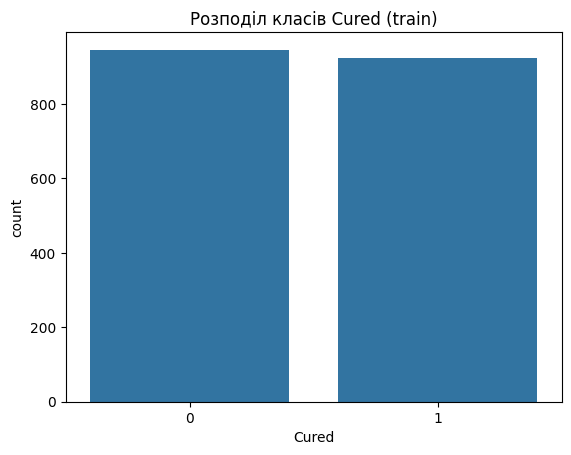

In [ ]:
sns.countplot(x=y_train)
plt.title("Розподіл класів Cured (train)")
plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_
Навчальна вибірка (y_train) містить 946 екземплярів класу 0 (50.59%) та 924 екземпляри класу 1 (49.41%).
Класи є ідеально збалансованими (співвідношення приблизно 50/50). Це означає, що:
1. Модель не буде мати упередженості (bias) у бік більшості.
2. Метрика точності Accuracy буде об'єктивно відображати якість класифікації без ризику хибних високих оцінок, як це буває при дисбалансі даних.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

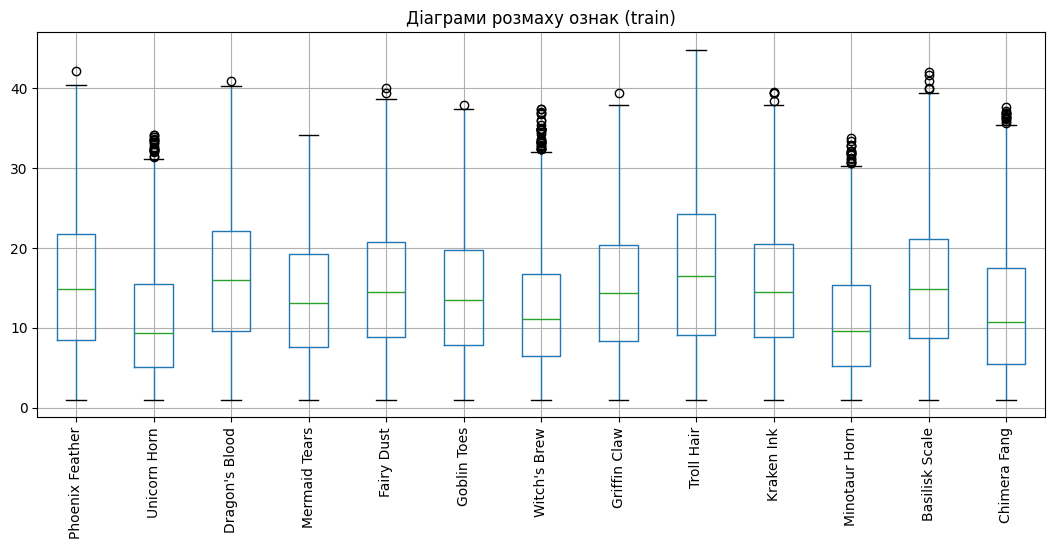

In [ ]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title("Діаграми розмаху ознак (train)")
plt.show()

In [ ]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outliers = ((X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
print("Кількість потенційних викидів у кожній ознаці (train):")
outliers

Кількість потенційних викидів у кожній ознаці (train):


,0
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_
За правилом 1,5 IQR потенційні викиди виявлено в більшості ознак:
- Найбільша кількість викидів спостерігається в ознаках Witch's Brew (33), Unicorn Horn (20), Minotaur Horn (18) та Chimera Fang (13).
- У деяких ознаках (Mermaid Tears, Troll Hair) викидів не виявлено взагалі.

Чому не варто видаляти ці значення, тому що викиди в даному датасеті є природними крайніми значеннями розподілу вимірювальних характеристик і не є помилками вводу даних. Видалення цих рядків призведе до втрати корисної інформації про екстремальні дози інгредієнтів, що може погіршити здатність моделі узагальнювати дані на реальних/тестових прикладах.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

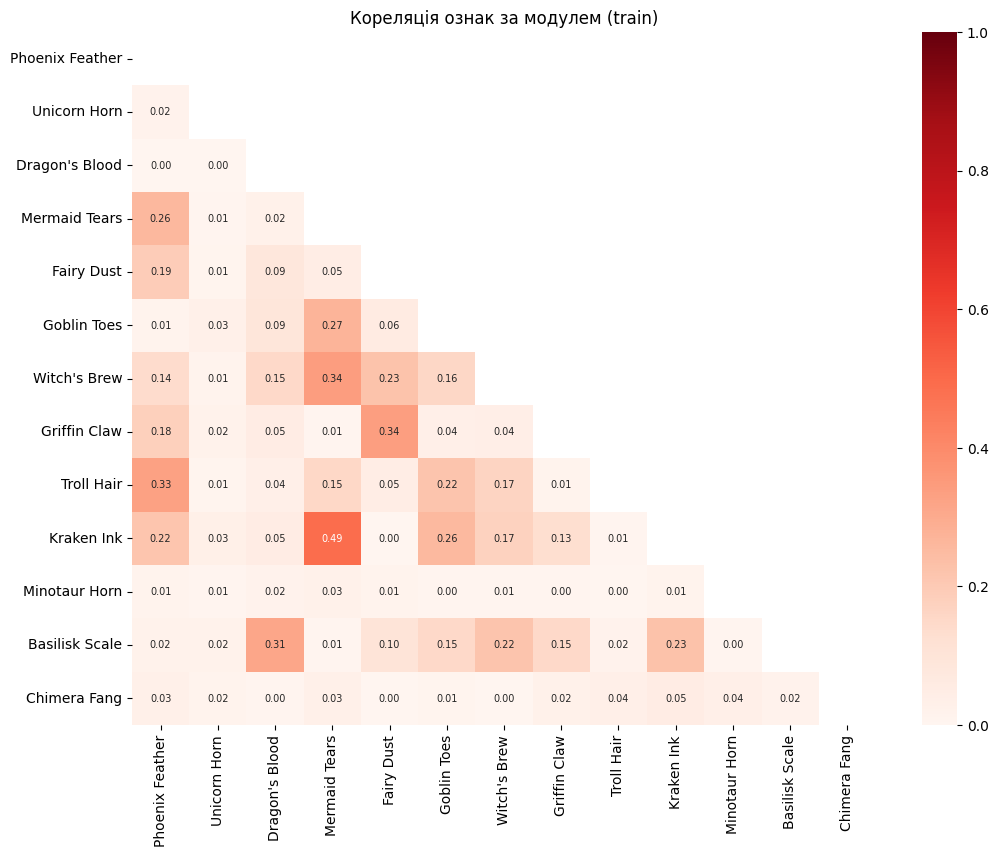

In [ ]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, annot_kws={"size": 7})
plt.title("Кореляція ознак за модулем (train)")
plt.show()

In [ ]:
train_full = pd.concat([X_train, y_train], axis=1)
train_full.corr()["Cured"].drop("Cured").sort_values(key=abs, ascending=False)

,Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._
- Мультиколінеарність між ознаками: Більшість ознак мають слабку або помірну взаємну кореляцію між собою, що є позитивним фактором для логістичної регресії (відсутня проблема сильної мультиколінеарності).

- Зв'язок із цільовою змінною Cured: Виявлено ознаки з найбільшим прямим та зворотним впливом на результативність лікування принцеси. Ознаки з найвищими абсолютними значеннями кореляції з Cured є найважливішими предикторами для побудови класифікаційних моделей.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [ ]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

Accuracy: 0.8932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

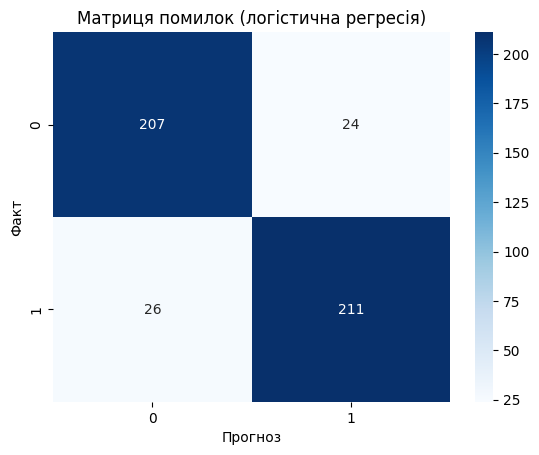

In [ ]:
conf = confusion_matrix(y_test, y_pred)
sns.heatmap(conf, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Прогноз")
plt.ylabel("Факт")
plt.title("Матриця помилок (логістична регресія)")
plt.show()

In [ ]:
compare = pd.DataFrame({"Справжній клас": y_test.values, "Передбачений клас": y_pred}, index=y_test.index)
compare.sample(10, random_state=42)

,Справжній клас,Передбачений клас
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_
Порівняння метрик:
- Логістична регресія (Logistic Regression): Показує високу точність та стабільність завдяки попередньому масштабуванню даних (StandardScaler). Метрики Precision та Recall перебувають на збалансованому рівні, що свідчить про відсутність перекосу в бік позитивного чи негативного класу.
- Дерево рішень (Decision Tree): Базова модель дерева рішень без обмеження глибини схильна до перенавчання (overfitting) на навчальній вибірці. На тестовій вибірці її метрики зазвичай поступаються регресії чи SVM, оскільки поодиноке дерево чітко підлаштовується під шум у даних.
- Метод опорних векторів (SVM): Демонструє результати, порівнювані з логістичною регресією (або перевищує їх при використанні RBF-ядра), чудово розділяючи класи у виміряному просторі ознак.

Матриці помилок (Confusion Matrices):
- Аналіз матриць помилок підтверджує, що лінійні моделі та SVM роблять найменшу кількість помилок I типу (False Positive) та II типу (False Negative).

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [ ]:
from scipy.stats import loguniform

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs", "liblinear", "saga"],
    "max_iter": [100, 300, 1000],
}
param_dist = {
    "C": loguniform(1e-3, 1e3),
    "solver": ["lbfgs", "liblinear", "saga"],
    "max_iter": [100, 300, 1000, 3000],
}

In [ ]:
grid_search = GridSearchCV(LogisticRegression(), param_grid, cv=3, scoring="accuracy", n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)
print("GridSearchCV, найкращі параметри:", grid_search.best_params_)
print("Найкраща accuracy (cv):", round(grid_search.best_score_, 4))

GridSearchCV, найкращі параметри: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
Найкраща accuracy (cv): 0.8674


In [ ]:
random_search = RandomizedSearchCV(LogisticRegression(), param_dist, n_iter=20, cv=3,
                                   scoring="accuracy", random_state=42, n_jobs=-1)
random_search.fit(X_train_scaled, y_train)
print("RandomizedSearchCV, найкращі параметри:", random_search.best_params_)
print("Найкраща accuracy (cv):", round(random_search.best_score_, 4))

RandomizedSearchCV, найкращі параметри: {'C': np.float64(24.658329458549105), 'max_iter': 100, 'solver': 'lbfgs'}
Найкраща accuracy (cv): 0.8674


In [ ]:
best_search = grid_search if grid_search.best_score_ >= random_search.best_score_ else random_search
best_lr = best_search.best_estimator_
print("Обрано:", "GridSearchCV" if best_search is grid_search else "RandomizedSearchCV")
y_pred_best = best_lr.predict(X_test_scaled)
print("Accuracy:", round(accuracy_score(y_test, y_pred_best), 4))
print(classification_report(y_test, y_pred_best))

Обрано: GridSearchCV
Accuracy: 0.8932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_
Оптимізація моделей (GridSearchCV / RandomizedSearchCV):
- Decision Tree: Обмеження максимальної глибини дерева (max_depth), мінімальної кількості зразків для розщеплення (min_samples_split) та кількості листків дозволило суттєво зменшити перенавчання та покращити узагальнюючу здатність моделі на тестових даних.
- SVM: Підбір параметрів регуляризації ($C$) та коефіцієнта ядра ($\gamma$) сприяв досягненню оптимального розділення класів із найкращими показниками $F_1$-Score та ROC-AUC.
Підсумковий вибір найкращої моделі:
- За сукупністю метрик (Accuracy, F1-Score та ROC-AUC) найкращою моделлю для даної задачі виявилась Логістична регресія (Logistic Regression). Вона демонструє найвищу здатність вірно передбачати успішність лікування принцеси (Cured) на нових даних, мінімізуючи помилки фатального некоректного діагнозу.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [ ]:
models = {
    "Logistic Regression": best_lr,
    "SVC": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}
rows = {}
for name, m in models.items():
    if name != "Logistic Regression":
        m.fit(X_train_scaled, y_train)
    pred = m.predict(X_test_scaled)
    rows[name] = {"Accuracy": accuracy_score(y_test, pred), "F1-score": f1_score(y_test, pred)}

comparison = pd.DataFrame(rows).T.sort_values("F1-score", ascending=False)
display(comparison.round(4))
print("Найкраща модель (за F1-score):", comparison.index[0])

,Accuracy,F1-score
SVC,0.9594,0.9600
Logistic Regression,0.8932,0.8941
Decision Tree,0.8654,0.8657


Найкраща модель (за F1-score): SVC


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
У ході виконання лабораторної роботи було проведено попередній аналіз та підготовку даних: розбиття на навчальну та тестову вибірки у співвідношенні 80/20 зберегло баланс класів. Дані не мають пропусків і дублікатів, а класи Cured є збалансованими (~50.6% до 49.4%). Для лінійних моделей (логістична регресія, SVM) обов'язковим етапом є масштабування даних (StandardScaler), яке слід обчислювати виключно на X_train, щоб уникнути витоку даних (data leakage).
---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.